# UTS Pembelajaran Mesin E
**NIM:** 202431116  
**Dataset:** Counter Strike 2 (prediksi `round_winner`)  
**Algoritma:** Naive Bayes dan K-Nearest Neighbors (KNN)

## 1. Import Library

In [1]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, auc)

sns.set_style('whitegrid')
RANDOM_STATE = 42

print("="*40); print("NIM: 202431116"); print("="*40)

NIM: 202431116


## 2. Load Dataset



In [2]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
try:
    from google.colab import files
    files.upload()
except ImportError:
    print('Bukan Google Colab, lewati upload.')

print("="*40); print("NIM: 202431116"); print("="*40)

Saving 03_counter_strike_2.csv to 03_counter_strike_2.csv
NIM: 202431116


In [3]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
df = pd.read_csv('03_counter_strike_2.csv')
print('Jumlah baris dan kolom:', df.shape)
df.head()

print("="*40); print("NIM: 202431116"); print("="*40)

Jumlah baris dan kolom: (2000, 14)
NIM: 202431116


## 3. Exploratory Data Analysis (EDA)

### 3.1 Informasi Dataset

In [4]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
df.info()

print("="*40); print("NIM: 202431116"); print("="*40)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   time_left     2000 non-null   float64
 1   ct_score      2000 non-null   float64
 2   t_score       2000 non-null   float64
 3   map           2000 non-null   object 
 4   bomb_planted  2000 non-null   bool   
 5   ct_health     2000 non-null   float64
 6   t_health      2000 non-null   float64
 7   ct_armor      2000 non-null   float64
 8   t_armor       2000 non-null   float64
 9   ct_money      2000 non-null   float64
 10  t_money       2000 non-null   float64
 11  ct_helmets    2000 non-null   float64
 12  t_helmets     2000 non-null   float64
 13  round_winner  2000 non-null   object 
dtypes: bool(1), float64(11), object(2)
memory usage: 205.2+ KB
NIM: 202431116


In [5]:
# NIM: 202431116 | UTS Pembelajaran Mesin 2026
df.describe().T

print("="*40); print("NIM: 202431116"); print("="*40)

NIM: 202431116


### 3.2 Missing Value, Duplikat, dan Distribusi Target

In [6]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
print('Missing value per kolom:')
print(df.isnull().sum())
print('\nJumlah data duplikat:', df.duplicated().sum())
print('\nDistribusi kelas round_winner:')
print(df['round_winner'].value_counts())
print(df['round_winner'].value_counts(normalize=True).round(4) * 100)

print("="*40); print("NIM: 202431116"); print("="*40)

Missing value per kolom:
time_left       0
ct_score        0
t_score         0
map             0
bomb_planted    0
ct_health       0
t_health        0
ct_armor        0
t_armor         0
ct_money        0
t_money         0
ct_helmets      0
t_helmets       0
round_winner    0
dtype: int64

Jumlah data duplikat: 39

Distribusi kelas round_winner:
round_winner
T     1176
CT     824
Name: count, dtype: int64
round_winner
T     58.8
CT    41.2
Name: proportion, dtype: float64
NIM: 202431116


### 3.3 Visualisasi Distribusi Data

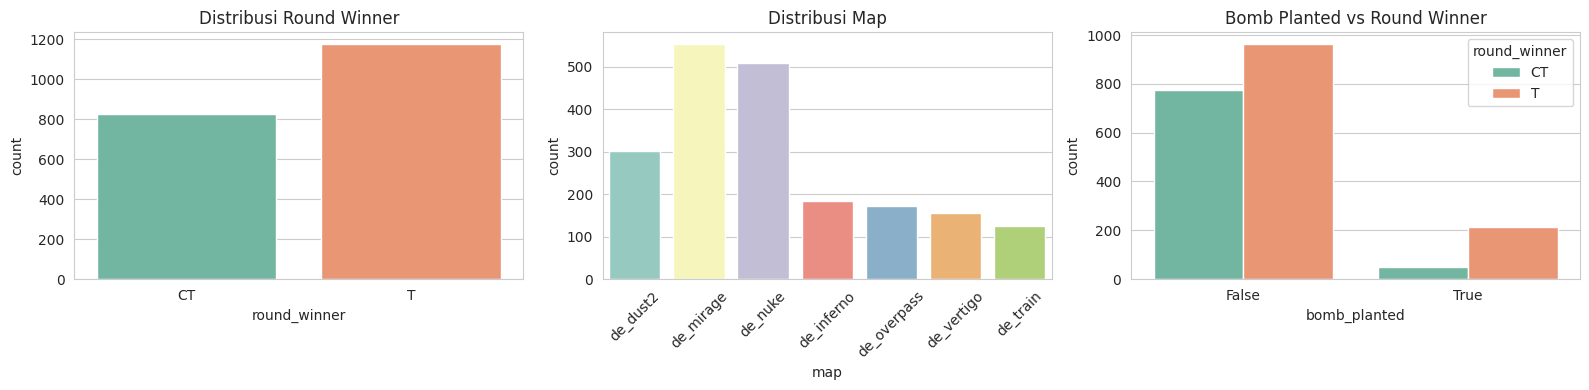

NIM: 202431116


In [7]:
# NIM: 202431116 | UTS Pembelajaran Mesin 2026
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x='round_winner', data=df, ax=ax[0], palette='Set2')
ax[0].set_title('Distribusi Round Winner')
sns.countplot(x='map', data=df, ax=ax[1], palette='Set3')
ax[1].set_title('Distribusi Map'); ax[1].tick_params(axis='x', rotation=45)
sns.countplot(x='bomb_planted', hue='round_winner', data=df, ax=ax[2], palette='Set2')
ax[2].set_title('Bomb Planted vs Round Winner')
plt.tight_layout()
plt.savefig('fig_01_distribusi.png', dpi=150)
plt.show()

print("="*40); print("NIM: 202431116"); print("="*40)

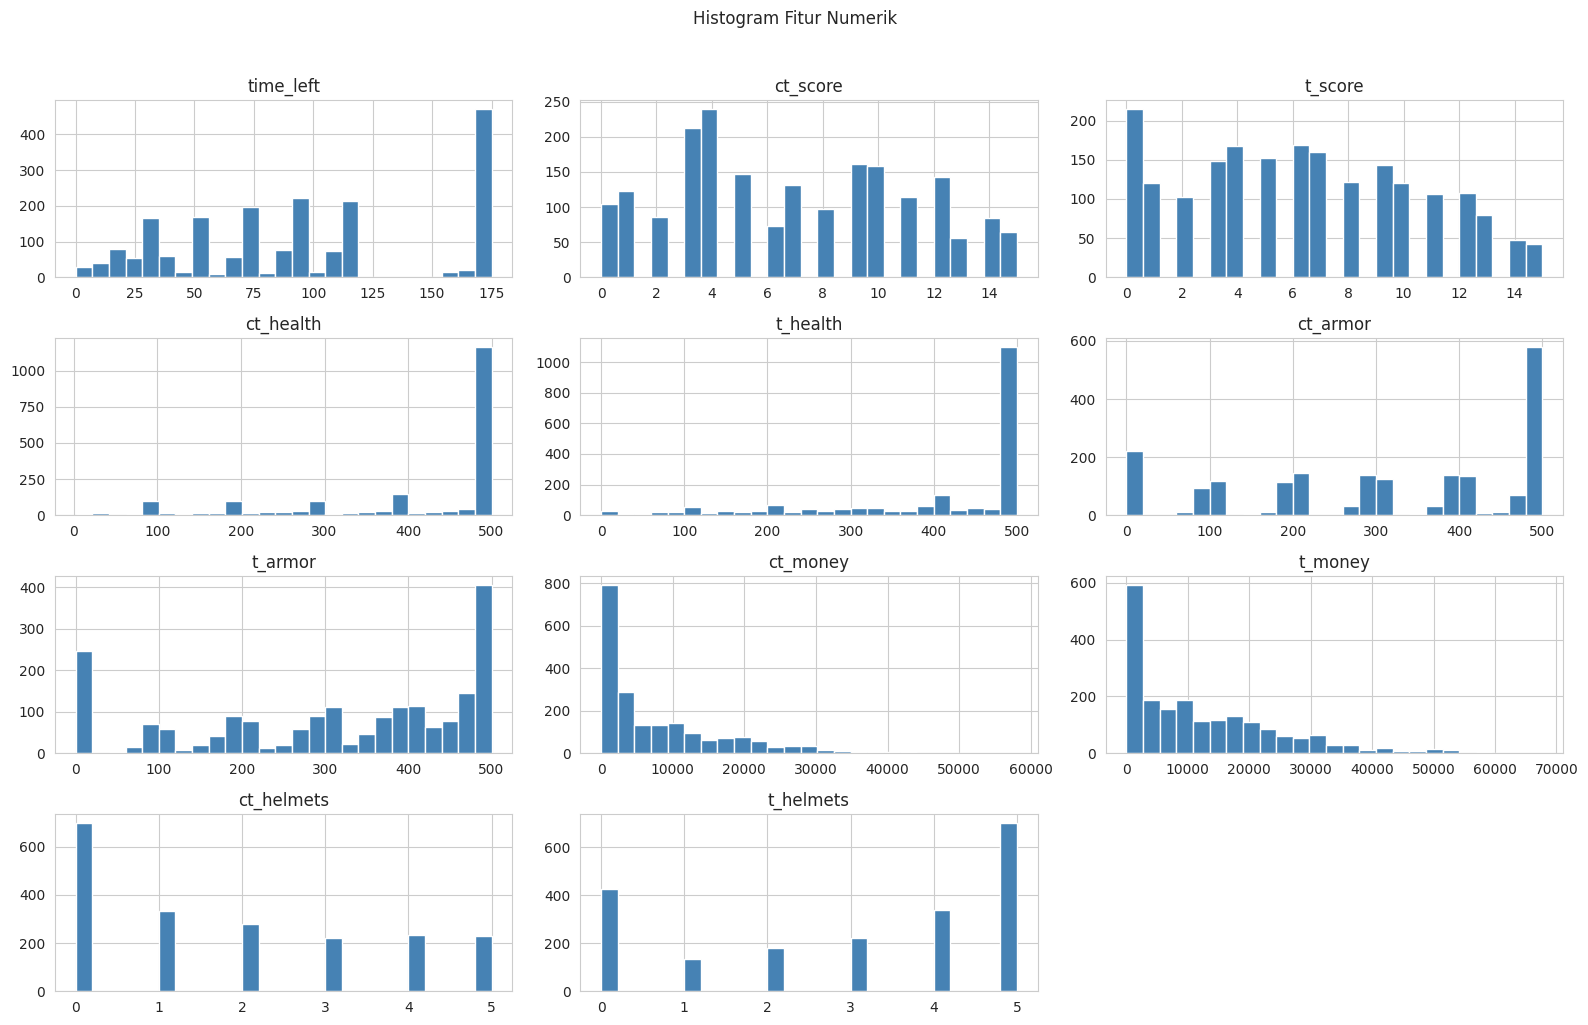

NIM: 202431116


In [8]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
num_cols = ['time_left','ct_score','t_score','ct_health','t_health','ct_armor','t_armor',
            'ct_money','t_money','ct_helmets','t_helmets']
df[num_cols].hist(bins=25, figsize=(16, 10), color='steelblue', edgecolor='white')
plt.suptitle('Histogram Fitur Numerik', y=1.02)
plt.tight_layout()
plt.savefig('fig_02_histogram.png', dpi=150)
plt.show()

print("="*40); print("NIM: 202431116"); print("="*40)

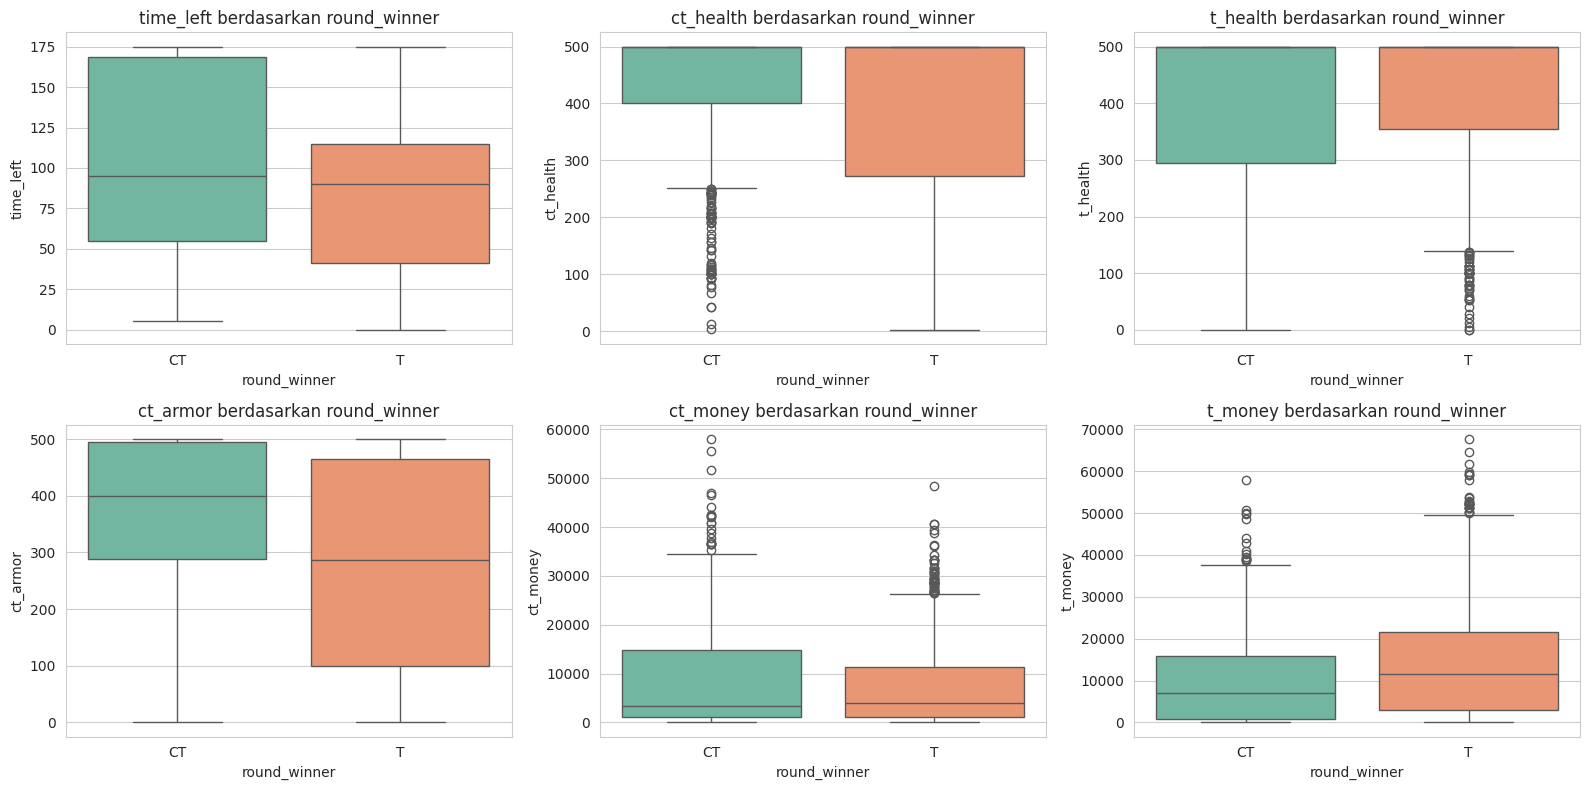

NIM: 202431116


In [9]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for a, c in zip(axes.ravel(), ['time_left','ct_health','t_health','ct_armor','ct_money','t_money']):
    sns.boxplot(x='round_winner', y=c, data=df, ax=a, palette='Set2')
    a.set_title(f'{c} berdasarkan round_winner')
plt.tight_layout()
plt.savefig('fig_03_boxplot.png', dpi=150)
plt.show()

print("="*40); print("NIM: 202431116"); print("="*40)

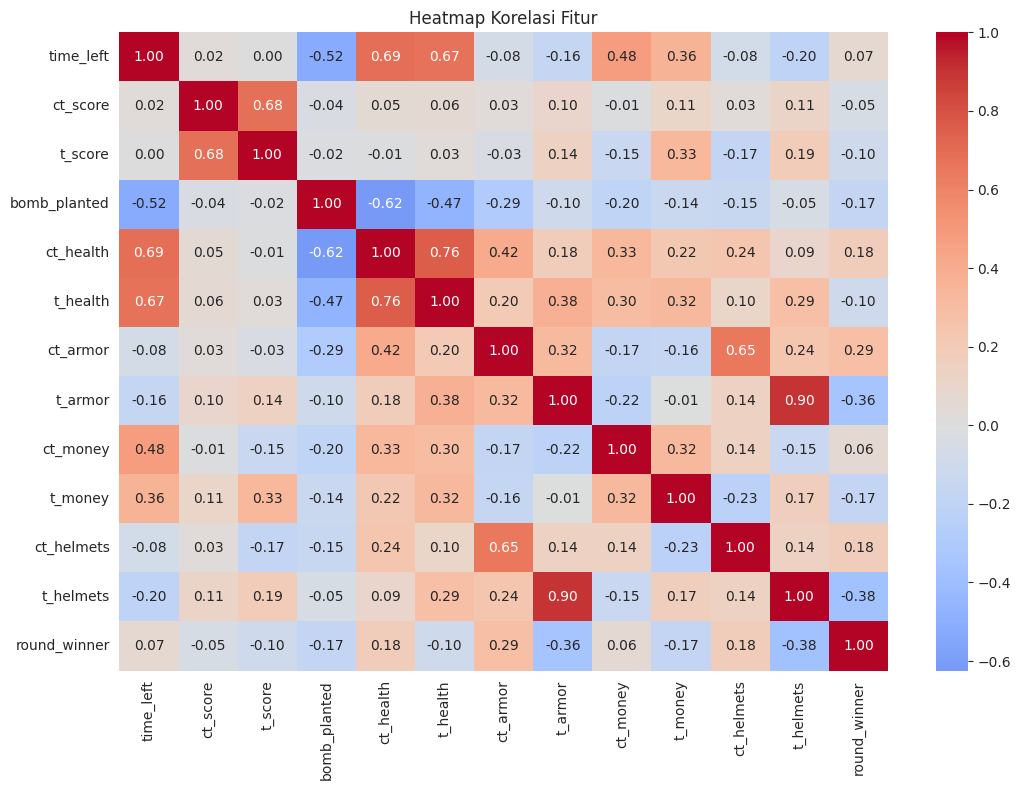

NIM: 202431116


In [10]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
df_corr = df.copy()
df_corr['bomb_planted'] = df_corr['bomb_planted'].astype(int)
df_corr['round_winner'] = (df_corr['round_winner'] == 'CT').astype(int)
plt.figure(figsize=(11, 8))
sns.heatmap(df_corr.drop(columns=['map']).corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Heatmap Korelasi Fitur')
plt.tight_layout()
plt.savefig('fig_04_korelasi.png', dpi=150)
plt.show()

print("="*40); print("NIM: 202431116"); print("="*40)

## 4. Preprocessing Data

### 4.1 Hapus Duplikat dan Deteksi Outlier (IQR)

In [11]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
df_clean = df.drop_duplicates().reset_index(drop=True)
print('Ukuran data sebelum :', df.shape)
print('Ukuran data sesudah :', df_clean.shape)

# Deteksi outlier dengan metode IQR (hanya dihitung, tidak dihapus)
outlier_info = {}
for c in num_cols:
    q1, q3 = df_clean[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_info[c] = ((df_clean[c] < q1 - 1.5*iqr) | (df_clean[c] > q3 + 1.5*iqr)).sum()
print('\nJumlah outlier per fitur (IQR):')
print(pd.Series(outlier_info))

print("="*40); print("NIM: 202431116"); print("="*40)

Ukuran data sebelum : (2000, 14)
Ukuran data sesudah : (1961, 14)

Jumlah outlier per fitur (IQR):
time_left      0
ct_score       0
t_score        0
ct_health      0
t_health      43
ct_armor       0
t_armor        0
ct_money      88
t_money       45
ct_helmets     0
t_helmets      0
dtype: int64
NIM: 202431116


### 4.2 Encoding Fitur Kategorikal dan Target

In [12]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
df_enc = df_clean.copy()
df_enc['bomb_planted'] = df_enc['bomb_planted'].astype(int)
df_enc = pd.get_dummies(df_enc, columns=['map'], drop_first=False, dtype=int)

le = LabelEncoder()
df_enc['round_winner'] = le.fit_transform(df_enc['round_winner'])
print('Kelas target:', dict(zip(le.classes_, le.transform(le.classes_))))
print('Jumlah fitur setelah encoding:', df_enc.shape[1] - 1)
df_enc.head()

print("="*40); print("NIM: 202431116"); print("="*40)

Kelas target: {'CT': np.int64(0), 'T': np.int64(1)}
Jumlah fitur setelah encoding: 19
NIM: 202431116


### 4.3 Split Data dan Standarisasi

In [13]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
X = df_enc.drop(columns=['round_winner'])
y = df_enc['round_winner']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   # fit hanya di data latih
X_test_sc  = scaler.transform(X_test)

print('X_train:', X_train_sc.shape, '| X_test:', X_test_sc.shape)
print('Distribusi y_train:', y_train.value_counts().to_dict())
print('Distribusi y_test :', y_test.value_counts().to_dict())

print("="*40); print("NIM: 202431116"); print("="*40)

X_train: (1568, 19) | X_test: (393, 19)
Distribusi y_train: {1: 924, 0: 644}
Distribusi y_test : {1: 232, 0: 161}
NIM: 202431116


## 5. Model 1: Naive Bayes (Gaussian)

Akurasi Naive Bayes: 0.7379

Classification Report:
              precision    recall  f1-score   support

          CT       0.70      0.62      0.66       161
           T       0.76      0.82      0.79       232

    accuracy                           0.74       393
   macro avg       0.73      0.72      0.72       393
weighted avg       0.74      0.74      0.73       393



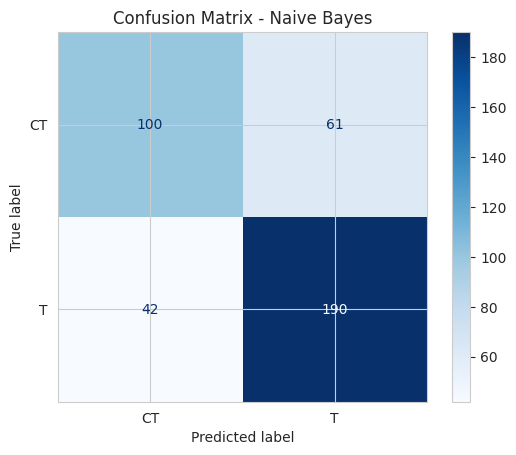

NIM: 202431116


In [14]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
nb = GaussianNB()
nb.fit(X_train_sc, y_train)
y_pred_nb = nb.predict(X_test_sc)

acc_nb = accuracy_score(y_test, y_pred_nb)
print(f'Akurasi Naive Bayes: {acc_nb:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_nb, target_names=le.classes_))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_nb), display_labels=le.classes_).plot(cmap='Blues')
plt.title('Confusion Matrix - Naive Bayes')
plt.savefig('fig_05_cm_nb.png', dpi=150, bbox_inches='tight')
plt.show()

print("="*40); print("NIM: 202431116"); print("="*40)

## 6. Model 2: K-Nearest Neighbors (KNN)

### 6.1 KNN Baseline (k = 5)

In [15]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
knn_base = KNeighborsClassifier(n_neighbors=5)
knn_base.fit(X_train_sc, y_train)
y_pred_knn_base = knn_base.predict(X_test_sc)
print(f'Akurasi KNN baseline (k=5): {accuracy_score(y_test, y_pred_knn_base):.4f}')

print("="*40); print("NIM: 202431116"); print("="*40)

Akurasi KNN baseline (k=5): 0.7990
NIM: 202431116


### 6.2 Pencarian Nilai k Terbaik

k terbaik (CV): 1 | akurasi CV: 0.8565


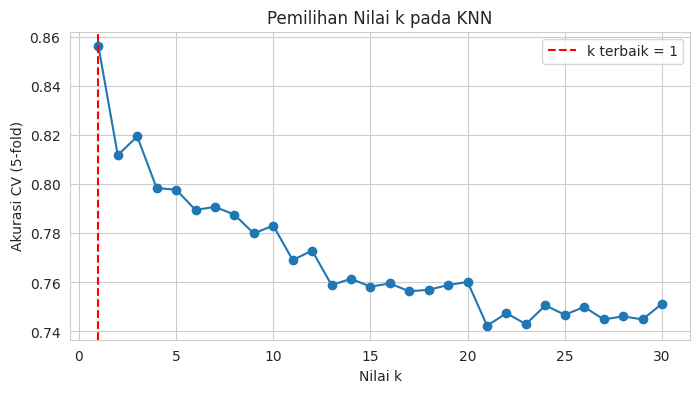

NIM: 202431116


In [16]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
k_range = range(1, 31)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_sc, y_train, cv=cv).mean()
             for k in k_range]

best_k = list(k_range)[int(np.argmax(cv_scores))]
print('k terbaik (CV):', best_k, '| akurasi CV:', round(max(cv_scores), 4))

plt.figure(figsize=(8, 4))
plt.plot(list(k_range), cv_scores, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'k terbaik = {best_k}')
plt.xlabel('Nilai k'); plt.ylabel('Akurasi CV (5-fold)')
plt.title('Pemilihan Nilai k pada KNN'); plt.legend()
plt.savefig('fig_06_k_vs_akurasi.png', dpi=150, bbox_inches='tight')
plt.show()

print("="*40); print("NIM: 202431116"); print("="*40)

### 6.3 Hyperparameter Tuning (GridSearchCV)

In [17]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
param_grid = {
    'n_neighbors': list(range(1, 31)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=cv, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_sc, y_train)
print('Parameter terbaik:', grid.best_params_)
print('Akurasi CV terbaik:', round(grid.best_score_, 4))

print("="*40); print("NIM: 202431116"); print("="*40)

Parameter terbaik: {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'distance'}
Akurasi CV terbaik: 0.8814
NIM: 202431116


### 6.4 Evaluasi KNN Terbaik

Akurasi KNN (tuned): 0.8702

Classification Report:
              precision    recall  f1-score   support

          CT       0.86      0.81      0.84       161
           T       0.88      0.91      0.89       232

    accuracy                           0.87       393
   macro avg       0.87      0.86      0.86       393
weighted avg       0.87      0.87      0.87       393



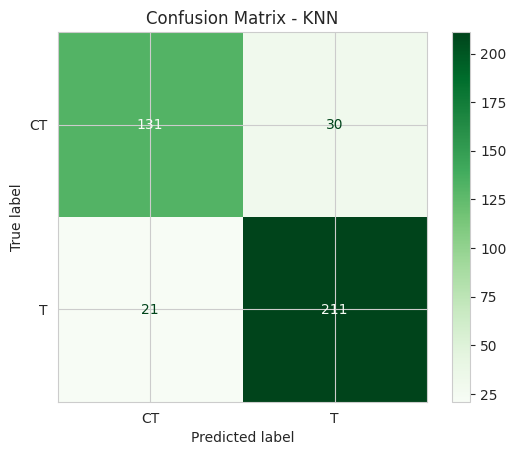

NIM: 202431116


In [18]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
knn = grid.best_estimator_
y_pred_knn = knn.predict(X_test_sc)

acc_knn = accuracy_score(y_test, y_pred_knn)
print(f'Akurasi KNN (tuned): {acc_knn:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_knn, target_names=le.classes_))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_knn), display_labels=le.classes_).plot(cmap='Greens')
plt.title('Confusion Matrix - KNN')
plt.savefig('fig_07_cm_knn.png', dpi=150, bbox_inches='tight')
plt.show()

print("="*40); print("NIM: 202431116"); print("="*40)

## 7. Perbandingan Model

      Model  Accuracy  Precision  Recall  F1-Score
Naive Bayes    0.7379     0.7354  0.7379    0.7349
        KNN    0.8702     0.8699  0.8702    0.8696


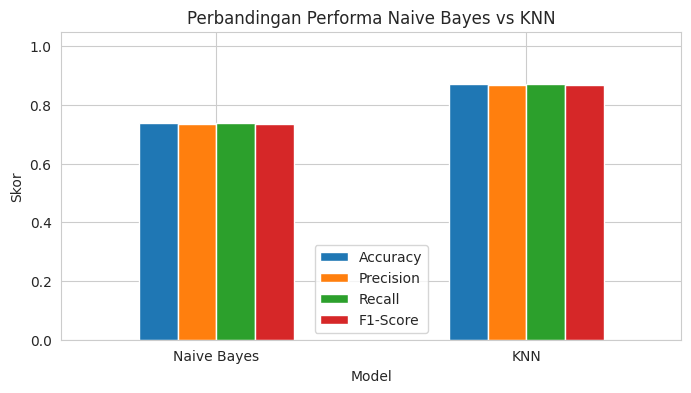

NIM: 202431116


In [19]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
hasil = pd.DataFrame({
    'Model': ['Naive Bayes', 'KNN'],
    'Accuracy':  [accuracy_score(y_test, y_pred_nb),  accuracy_score(y_test, y_pred_knn)],
    'Precision': [precision_score(y_test, y_pred_nb, average='weighted'), precision_score(y_test, y_pred_knn, average='weighted')],
    'Recall':    [recall_score(y_test, y_pred_nb, average='weighted'),    recall_score(y_test, y_pred_knn, average='weighted')],
    'F1-Score':  [f1_score(y_test, y_pred_nb, average='weighted'),        f1_score(y_test, y_pred_knn, average='weighted')],
}).round(4)
print(hasil.to_string(index=False))

hasil.set_index('Model').plot(kind='bar', figsize=(8, 4), ylim=(0, 1.05), rot=0)
plt.title('Perbandingan Performa Naive Bayes vs KNN')
plt.ylabel('Skor')
plt.savefig('fig_08_perbandingan.png', dpi=150, bbox_inches='tight')
plt.show()

print("="*40); print("NIM: 202431116"); print("="*40)

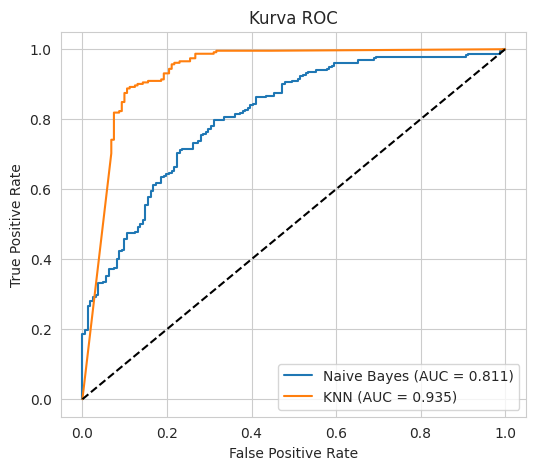

NIM: 202431116


In [20]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
plt.figure(figsize=(6, 5))
for nama, model in [('Naive Bayes', nb), ('KNN', knn)]:
    prob = model.predict_proba(X_test_sc)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{nama} (AUC = {auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('Kurva ROC'); plt.legend()
plt.savefig('fig_09_roc.png', dpi=150, bbox_inches='tight')
plt.show()

print("="*40); print("NIM: 202431116"); print("="*40)

In [21]:
# Arya Shahryar Asis 202431116 | UTS Pembelajaran Mesin E
# Cross-validation 5-fold untuk memeriksa kestabilan model
cv_nb  = cross_val_score(GaussianNB(), X_train_sc, y_train, cv=cv)
cv_knn = cross_val_score(knn, X_train_sc, y_train, cv=cv)
print(f'Naive Bayes : {cv_nb.mean():.4f} +/- {cv_nb.std():.4f}')
print(f'KNN         : {cv_knn.mean():.4f} +/- {cv_knn.std():.4f}')

print("="*40); print("NIM: 202431116"); print("="*40)

Naive Bayes : 0.7213 +/- 0.0102
KNN         : 0.8814 +/- 0.0126
NIM: 202431116
